# **Pós-Graduação em Data Science and Digital Transformation**

## *Tópicos Avançados de Aprendizagem Máquina*

### Ana Estreia
---

> # Trabalho Prático — Deteção de Imagens Geradas por IA

**Dataset:** CIFAKE — Real and AI-Generated Synthetic Images  
**Repositório:** https://github.com/jordan-bird/CIFAKE-Real-and-AI-Generated-Synthetic-Images.git

---


## 1. Configuração do Ambiente

### 1.1 Montar o Google Drive e preparar os dados


In [ ]:
from google.colab import drive
drive.mount('/gdrive')


Mounted at /gdrive


In [ ]:
import zipfile
import os

zip_path = '/gdrive/MyDrive/TAAM/CIFAKE.zip'
dest = '/content/CIFAKE'

with zipfile.ZipFile(zip_path, 'r') as z:
    prefix = 'CIFAKE-Real-and-AI-Generated-Synthetic-Images-main/DATASET/'
    for member in z.namelist():
        if member.startswith(prefix):
            new_path = os.path.join(dest, member[len(prefix):])
            if member.endswith('/'):
                os.makedirs(new_path, exist_ok=True)
            else:
                os.makedirs(os.path.dirname(new_path), exist_ok=True)
                with z.open(member) as src, open(new_path, 'wb') as dst:
                    dst.write(src.read())

print('Dataset extraído.')


Dataset extraído.


### 1.2 Importações


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gc

import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten,
    Dense, Dropout, BatchNormalization
)
from tensorflow.keras.utils import load_img, img_to_array
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import optimizers
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input

from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score
)
import seaborn as sns

print(f'TensorFlow version: {tf.__version__}')
print(f'GPU disponível: {tf.config.list_physical_devices("GPU")}')


TensorFlow version: 2.20.0
GPU disponível: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
## 2. Exploração e Pré-Processamento de Dados

### 2.1 Preparação dos dados

Utiliza-se o `ImageDataGenerator` com `flow_from_directory()` para leitura eficiente das imagens em lotes, evitando esgotar a memória RAM do Colab com o dataset completo (120 000 imagens).  
O split de validação é criado automaticamente a partir dos dados de treino (15%).


In [ ]:
# Diretórios dos dados
train_dir = '/content/CIFAKE/train'
test_dir  = '/content/CIFAKE/test'

IMG_SIZE   = (32, 32)
BATCH_SIZE = 32

# Gerador de treino + split de validação
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.15
)
# Dados de treino
train_generator = datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary', # REAL vs FAKE
    subset='training',
    #seed=42
)
# Dados de validação
val_generator = datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',
    #seed=42
)

test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False # Importante para avaliação e matrizes de confusão
)

CLASS_NAMES = list(train_generator.class_indices.keys())
print('Classes:', CLASS_NAMES)
print('Índices:', train_generator.class_indices)


Found 85000 images belonging to 2 classes.
Found 15000 images belonging to 2 classes.
Found 20000 images belonging to 2 classes.
Classes: ['FAKE', 'REAL']
Índices: {'FAKE': 0, 'REAL': 1}


### 2.2 Análise Exploratória do Dataset


In [ ]:
# Distribuição de classes
def print_class_distribution(generator, titulo):
    labels = generator.classes
    unique, counts = np.unique(labels, return_counts=True)
    class_names = list(generator.class_indices.keys())

    for cls, cnt in zip([class_names[i] for i in unique], counts):
        print(f'  {cls}: {cnt} imagens ({cnt/sum(counts)*100:.1f}%)')

print('=== Conjunto de Treino ===')
print_class_distribution(train_generator, 'Distribuição de Classes — Treino')

print('\n=== Conjunto de Teste ===')
print_class_distribution(test_generator, 'Distribuição de Classes — Teste')


=== Conjunto de Treino ===
  FAKE: 42500 imagens (50.0%)
  REAL: 42500 imagens (50.0%)

=== Conjunto de Teste ===
  FAKE: 10000 imagens (50.0%)
  REAL: 10000 imagens (50.0%)


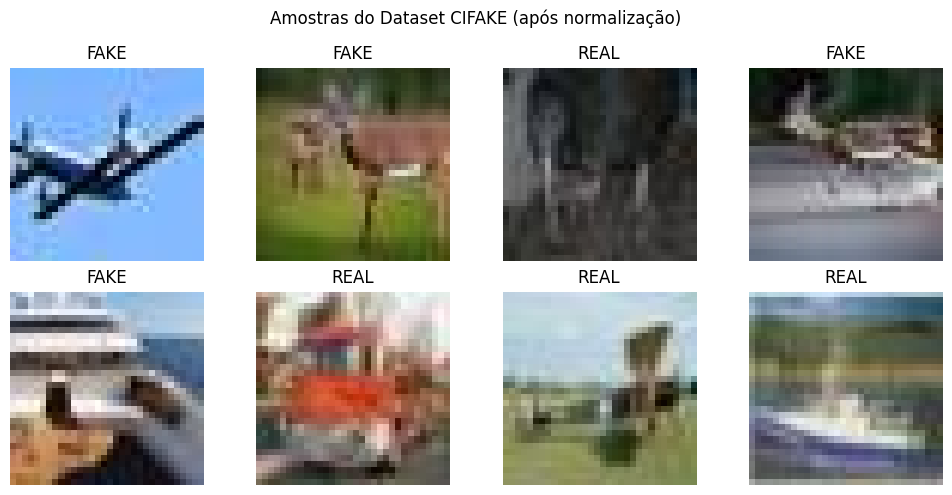

In [ ]:
# Visualização de amostras
images, labels = next(train_generator)

plt.figure(figsize=(10, 5))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i])
    plt.title(CLASS_NAMES[int(labels[i])])
    plt.axis('off')
plt.suptitle('Amostras do Dataset CIFAKE (após normalização)')
plt.tight_layout()
plt.show()


In [ ]:
# Estatísticas básicas das imagens
print(f'Dimensão das imagens de entrada : {images[0].shape}')
print(f'\nTotal de imagens de treino      : {train_generator.samples}')
print(f'Total de imagens de validação   : {val_generator.samples}')
print(f'Total de imagens de teste       : {test_generator.samples}')


Dimensão das imagens de entrada : (32, 32, 3)

Total de imagens de treino      : 85000
Total de imagens de validação   : 15000
Total de imagens de teste       : 20000


---
## 3. Funções Auxiliares

Definição de funções reutilizáveis para visualização de desempenho e avaliação dos modelos.


In [ ]:
def plot_history(history, titulo):
    """Plota curvas de exactidão e de custo de treino/validação."""
    epocas_treinadas = len(history.history['accuracy'])
    f, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    f.suptitle(titulo, fontsize=12)

    ax1.plot(history.history['accuracy'][:epocas_treinadas], label='Treino')
    ax1.plot(history.history['val_accuracy'][:epocas_treinadas], label='Validação')
    ax1.set_xticks(np.arange(0, epocas_treinadas+1, 5))
    ax1.set_xlabel('Época')
    # ax1.set_ylabel('Exatidão')
    ax1.set_title('Exatidão')
    ax1.legend()

    ax2.plot(history.history['loss'][:epocas_treinadas], label='Treino')
    ax2.plot(history.history['val_loss'][:epocas_treinadas], label='Validação')
    ax2.set_xticks(np.arange(0, epocas_treinadas+1, 5))
    ax2.set_xlabel('Época')
    # ax2.set_ylabel('Função de Custo')
    ax2.set_title('Função de Custo')
    ax2.legend()

    plt.tight_layout()
    plt.show()
    print(f'Épocas treinadas: {epocas_treinadas}')

In [ ]:
def plot_confusion_matrix(y_true, y_pred, titulo, class_names):
    """calcular e visualizar matriz de confusão"""
    # if class_names is None:
    #     class_names = ['FAKE', 'REAL']
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='.2%', cmap='Greens',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(titulo)
    plt.xlabel('Rótulo Previsto')
    plt.ylabel('Rótulo Verdadeiro')
    plt.tight_layout()
    plt.show()
    print(classification_report(y_true, y_pred, target_names=class_names))


In [ ]:
# DataFrame global para comparar todos os modelos
performance = pd.DataFrame(columns=['Train Acc', 'Val Acc', 'Test Acc'])

def avaliar_modelo(modelo, nome, generator=test_generator,
                   train_gen=train_generator, val_gen=val_generator):
    """Avalia um modelo e atualiza a tabela comparativa."""
    # Previsões no conjunto de teste
    generator.reset()
    y_pred_prob = modelo.predict(generator, verbose=0)
    y_pred = (y_pred_prob > 0.5).astype(int).flatten()
    y_true = generator.classes

    # Matriz de confusão
    class_names = list(generator.class_indices.keys())
    plot_confusion_matrix(y_true, y_pred, f'Matriz de Confusão — {nome}', class_names)

    # Métricas
    train_acc = modelo.evaluate(train_gen, verbose=0)[1]
    val_acc   = modelo.evaluate(val_gen,   verbose=0)[1]
    test_acc  = accuracy_score(y_true, y_pred)

    performance.loc[nome] = [train_acc, val_acc, test_acc]
    print('\n--- Tabela Comparativa (até ao momento) ---')
    display(performance.style.format('{:.4f}'))

    return y_pred, y_true, y_pred_prob


---
## 4. Modelo 1 — CNN Treinada de Raiz


### 4.1 Arquitetura

A arquitetura definida no enunciado é a seguinte:

```
Conv2D(32, 3×3) → ReLU → Conv2D(32, 3×3) → ReLU → MaxPool(2×2)
Conv2D(64, 3×3) → ReLU → Conv2D(64, 3×3) → ReLU → MaxPool(2×2)
Conv2D(128, 3×3) → ReLU → MaxPool(2×2)
Flatten → Dense(256) → ReLU → Dropout(0.5) → Dense(1) → Sigmoid
```

Como se trata de classificação binária (REAL vs FAKE), utiliza-se:
- Função de custo: `binary_crossentropy`
- Neurónio de saída com ativação `sigmoid` (probabilidade [0, 1])


In [ ]:
def build_cnn_scratch(input_shape=(32, 32, 3)):
    """Constrói a CNN de raiz com a arquitetura definida no enunciado."""
    model = Sequential()
    # Camada de entrada
    model.add(Input(shape=input_shape))
    # Camada 1
    model.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))
    model.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))
    model.add(MaxPooling2D(2, 2))
    # Camada 2
    model.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
    model.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
    model.add(MaxPooling2D(2, 2))
    # Camada 3
    model.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
    model.add(MaxPooling2D(2, 2))
    # Flatten
    model.add(Flatten())
    # Camada densa
    model.add(Dense(256, activation='relu'))
    model.add(Dropout(0.5))
    # Camada de saída
    model.add(Dense(1, activation='sigmoid'))

    return model


In [ ]:
cnn_scratch = build_cnn_scratch()
cnn_scratch.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 172,705 (674.63 KB)

 Trainable params: 172,705 (674.63 KB)

 Non-trainable params: 0 (0.00 B)

### 4.2 Localização para Gravar os Modelos

Tal como na aula, os modelos são gravados no Google Drive para não serem perdidos quando a sessão do Colab termina.

In [ ]:
# Caminho base no Google Drive para guardar os modelos
# (garante que não se perdem quando a sessão do Colab terminar)
MODEL_PATH = '/gdrive/MyDrive/TAAM/modelos_cifake/'
os.makedirs(MODEL_PATH, exist_ok=True)
print(f'Modelos serão gravados em: {MODEL_PATH}')

Modelos serão gravados em: /gdrive/MyDrive/TAAM/modelos_cifake/


### 4.3 Treino do Modelo Baseline

Primeiro treino com hiperparâmetros base: otimizador **Adam** com `learning_rate=0.001`, `batch_size=32`.

Utiliza-se **EarlyStopping** (como nas aulas) para interromper o treino quando a função de custo de validação deixa de melhorar, evitando overfitting e poupando tempo de computação.  
O parâmetro `restore_best_weights=True` garante que o modelo fica com os pesos da época de melhor desempenho.


In [ ]:
cnn_scratch.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True,
    verbose=1
)

In [ ]:
history_cnn = cnn_scratch.fit(
    train_generator,
    validation_data=val_generator,
    batch_size=32,
    epochs=30,
    callbacks=[early_stop]
)


Epoch 1/30
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 51s 17ms/step - accuracy: 0.8308 - loss: 0.3790 - val_accuracy: 0.8847 - val_loss: 0.2775
Epoch 2/30
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 40s 15ms/step - accuracy: 0.8924 - loss: 0.2639 - val_accuracy: 0.8975 - val_loss: 0.2502
Epoch 3/30
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 38s 14ms/step - accuracy: 0.9041 - loss: 0.2376 - val_accuracy: 0.9095 - val_loss: 0.2209
Epoch 4/30
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 50s 19ms/step - accuracy: 0.9134 - loss: 0.2192 - val_accuracy: 0.8988 - val_loss: 0.2481
Epoch 5/30
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 39s 15ms/step - accuracy: 0.9202 - loss: 0.2023 - val_accuracy: 0.9240 - val_loss: 0.1937
Epoch 6/30
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 37s 14ms/step - accuracy: 0.9250 - loss: 0.1906 - val_accuracy: 0.9125 - val_loss: 0.2223
Epoch 7/30
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 39s 15ms/step - accuracy: 0.9285 - loss: 0.1804 - val_accuracy: 0.9146 - val_loss: 0.2118
Epoch 8/30
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 39s 15ms/step - accuracy: 0.9339 -

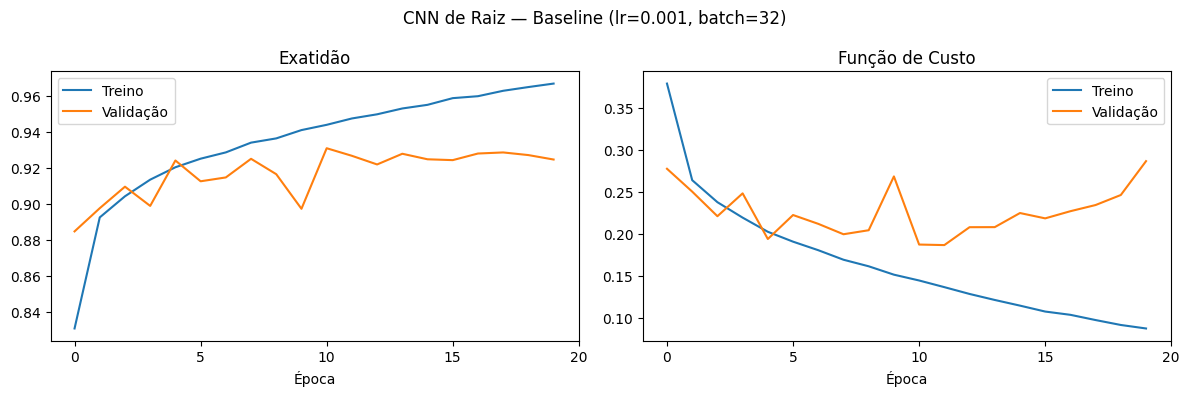

Épocas treinadas: 20


In [ ]:
plot_history(history_cnn, 'CNN de Raiz — Baseline (lr=0.001, batch=32)')


#### Gravação do modelo

Grava-se o modelo após o treino, seguindo a abordagem das aulas.
Desta forma, é possível retomá-lo numa sessão futura sem re-treinar.

In [ ]:
cnn_scratch.save(MODEL_PATH + 'cnn_scratch_baseline.keras')
print('Modelo gravado:', MODEL_PATH + 'cnn_scratch_baseline.keras')

Modelo gravado: /gdrive/MyDrive/TAAM/modelos_cifake/cnn_scratch_baseline.keras


#### Recarregar modelo (caso a sessão tenha sido reiniciada)

Se a sessão do Colab tiver sido reiniciada, executar a célula seguinte para recuperar o modelo gravado, em vez de re-treinar.


In [ ]:
# Descomentar apenas se necessário recarregar o modelo
cnn_scratch = load_model(MODEL_PATH + 'cnn_scratch_baseline.keras')
print('Modelo recarregado com sucesso.')

Modelo recarregado com sucesso.


### 4.4 Avaliação do Modelo Baseline


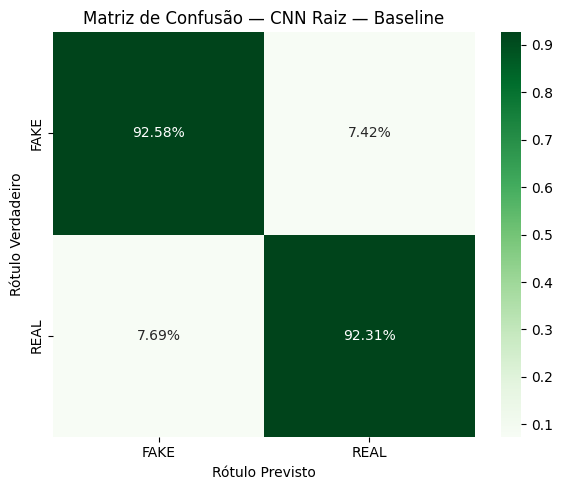

              precision    recall  f1-score   support

        FAKE       0.92      0.93      0.92     10000
        REAL       0.93      0.92      0.92     10000

    accuracy                           0.92     20000
   macro avg       0.92      0.92      0.92     20000
weighted avg       0.92      0.92      0.92     20000


--- Tabela Comparativa (até ao momento) ---


,Train Acc,Val Acc,Test Acc
CNN Raiz — Baseline,0.9582,0.9266,0.9244


In [ ]:
preds_cnn, true_cnn, prob_cnn = avaliar_modelo(
    cnn_scratch, 'CNN Raiz — Baseline'
)


### 4.5 Experiência com Diferentes Hiperparâmetros

Como sugerido, experimenta-se variar a taxa de aprendizagem e o batch size para perceber o seu efeito no desempenho e na estabilidade do treino.  

Testam-se duas variações relativamente ao baseline:

| Parâmetro | Baseline | Variante |
|-----------|----------|----------|
| `learning_rate` | 0.001 | **0.0001** |
| `batch_size` | 32 | **64** |

Uma taxa de aprendizagem mais baixa produz atualizações de pesos mais graduais, reduzindo o risco de divergência. Um batch maior torna os gradientes mais estáveis porque são calculados sobre mais exemplos por iteração.

In [ ]:
# Hiperparâmetros alternativos: learning rate menor + batch size maior
datagen_bs64 = ImageDataGenerator(rescale=1./255, validation_split=0.15)

train_gen_bs64 = datagen_bs64.flow_from_directory(
    train_dir, target_size=IMG_SIZE, batch_size=64,
    class_mode='binary', subset='training'
)
val_gen_bs64 = datagen_bs64.flow_from_directory(
    train_dir, target_size=IMG_SIZE, batch_size=64,
    class_mode='binary', subset='validation'
)

Found 85000 images belonging to 2 classes.
Found 15000 images belonging to 2 classes.


In [ ]:
cnn_scratch_v2 = build_cnn_scratch()
cnn_scratch_v2.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 172,705 (674.63 KB)

 Trainable params: 172,705 (674.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cnn_scratch_v2.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop2 = EarlyStopping(monitor='val_loss', patience=8,
                             restore_best_weights=True, verbose=1)

In [ ]:
history_cnn_v2 = cnn_scratch_v2.fit(
    train_gen_bs64,
    validation_data=val_gen_bs64,
    batch_size=64,
    epochs=40,
    callbacks=[early_stop2]
)


Epoch 1/40
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 40s 27ms/step - accuracy: 0.7721 - loss: 0.4740 - val_accuracy: 0.8285 - val_loss: 0.3922
Epoch 2/40
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 33s 25ms/step - accuracy: 0.8475 - loss: 0.3554 - val_accuracy: 0.8621 - val_loss: 0.3272
Epoch 3/40
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 31s 23ms/step - accuracy: 0.8725 - loss: 0.3085 - val_accuracy: 0.8854 - val_loss: 0.2795
Epoch 4/40
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 31s 23ms/step - accuracy: 0.8854 - loss: 0.2803 - val_accuracy: 0.8884 - val_loss: 0.2694
Epoch 5/40
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 32s 24ms/step - accuracy: 0.8936 - loss: 0.2634 - val_accuracy: 0.8975 - val_loss: 0.2534
Epoch 6/40
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 32s 24ms/step - accuracy: 0.9010 - loss: 0.2462 - val_accuracy: 0.9085 - val_loss: 0.2237
Epoch 7/40
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 31s 23ms/step - accuracy: 0.9070 - loss: 0.2324 - val_accuracy: 0.9139 - val_loss: 0.2156
Epoch 8/40
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 31s 24ms/step - accuracy: 0.9122 -

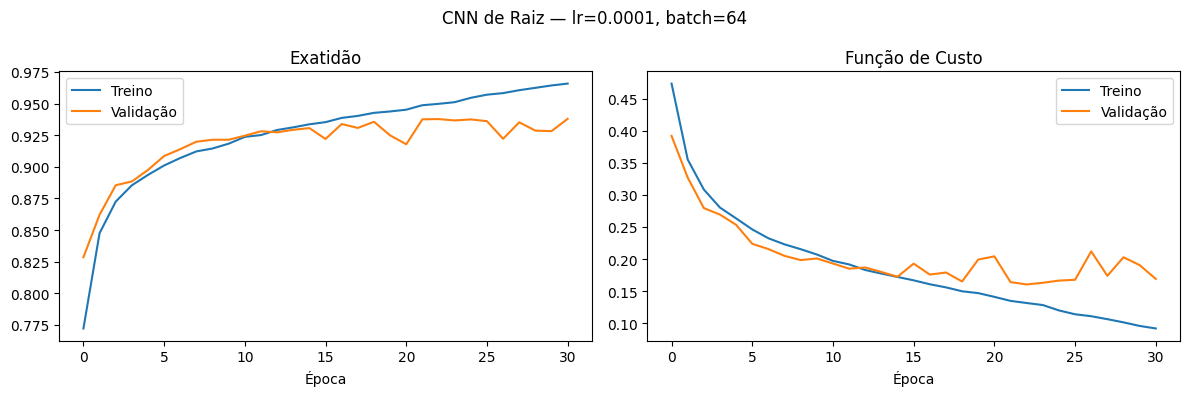

Épocas treinadas: 31


In [ ]:
plot_history(history_cnn_v2, 'CNN de Raiz — lr=0.0001, batch=64')


In [ ]:
cnn_scratch_v2.save(MODEL_PATH + 'cnn_scratch_v2_lr1e4_bs64.keras')
print('Modelo v2 gravado.')

Modelo v2 gravado.


In [ ]:
# Descomentar apenas se necessário recarregar
cnn_scratch_v2 = load_model(MODEL_PATH + 'cnn_scratch_v2_lr1e4_bs64.keras')

Found 20000 images belonging to 2 classes.


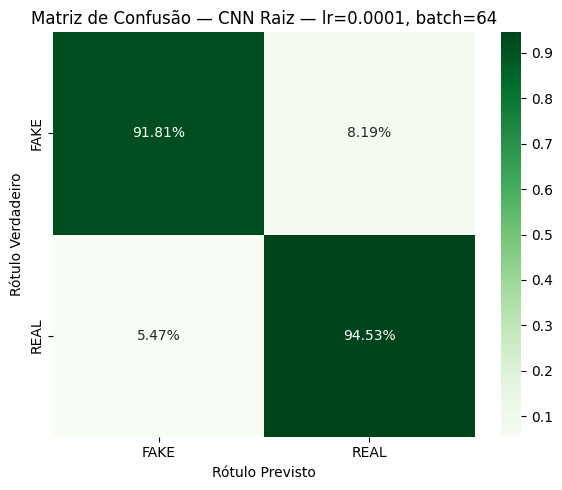

              precision    recall  f1-score   support

        FAKE       0.94      0.92      0.93     10000
        REAL       0.92      0.95      0.93     10000

    accuracy                           0.93     20000
   macro avg       0.93      0.93      0.93     20000
weighted avg       0.93      0.93      0.93     20000


--- Tabela Comparativa (até ao momento) ---


,Train Acc,Val Acc,Test Acc
CNN Raiz — Baseline,0.9582,0.9266,0.9244
"CNN Raiz — lr=0.0001, batch=64",0.9594,0.9377,0.9317


In [ ]:
# Avaliar com o mesmo gerador de teste
test_gen_eval = test_datagen.flow_from_directory(
    test_dir, target_size=IMG_SIZE, batch_size=64,
    class_mode='binary', shuffle=False
)

preds_cnn_v2, true_cnn_v2, prob_cnn_v2 = avaliar_modelo(
    cnn_scratch_v2, 'CNN Raiz — lr=0.0001, batch=64',
    generator=test_gen_eval,
    train_gen=train_gen_bs64, val_gen=val_gen_bs64
)


**Discussão:**

Os dois modelos atingem resultados semelhantes no conjunto de teste (92,44% vs 93,17%), mas com padrões de treino distintos. O baseline convergiu mais rapidamente (20 épocas vs 31), mas com curvas de validação mais instáveis. A variante com lr=0.0001 e batch=64 apresenta uma convergência mais suave e um gap treino/validação ligeiramente menor, indicando melhor generalização. É por isso a configuração preferível, ao custo de um treino mais longo.


---
## 5. Modelo 2 — Transfer Learning com VGG16

### 5.1 Abordagem A: Extração de Características e Data Augmentation

> **Nota sobre a abordagem de extração:** Existem duas formas de usar o VGG16 como extrator de características.
> A abordagem clássica pré-computa as características de todas as imagens antes do treino
> (`vgg_model.predict(train_imgs)`), sendo mais eficiente quando não há data augmentation.
> Como neste trabalho se utiliza data augmentation, opta-se pela abordagem integrada: o VGG16
> (com pesos congelados) é passado como primeira camada do modelo Sequential, e a extração de
> características ocorre automaticamente. Desta forma, cada época vê versões
> diferentes das imagens, aproveitando o efeito regularizador do augmentation.

> **Nota sobre o tamanho das imagens:** O VGG16 foi originalmente treinado com imagens 224×224. As imagens CIFAKE têm 32×32. Para transfer learning, redimensionam-se para **48×48**, valor mínimo adequado para a VGG16 processar sem erros nas camadas de pooling, mantendo o custo computacional reduzido.


In [ ]:
# Redimensionamento para 48×48 (mínimo viável para o VGG16)
VGG_SIZE = (48, 48)


vgg_train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    width_shift_range=0.1,
    height_shift_range=0.1,
    rotation_range=10,
)

vgg_train_gen = vgg_train_datagen.flow_from_directory(
    train_dir, target_size=VGG_SIZE, batch_size=64,
    class_mode='binary', subset='training',
)

vgg_val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.15
)
vgg_val_gen = vgg_val_datagen.flow_from_directory(
    train_dir, target_size=VGG_SIZE, batch_size=64,
    class_mode='binary', subset='validation',
)
test_datagen = ImageDataGenerator(rescale=1./255)
vgg_test_gen = test_datagen.flow_from_directory(
    test_dir, target_size=VGG_SIZE, batch_size=64,
    class_mode='binary', shuffle=False
)
print('Geradores VGG criados.')


Found 85000 images belonging to 2 classes.
Found 15000 images belonging to 2 classes.
Found 20000 images belonging to 2 classes.
Geradores VGG criados.


In [ ]:
# Carregar VGG16 sem as camadas densas do topo
vgg_base = VGG16(weights='imagenet', include_top=False,
                  input_shape=(48, 48, 3))

# Output da última camada convolucional
output = vgg_base.layers[-1].output
# aplicar Flatten ao output
output = Flatten()(output)

# Criar o modelo extrator e congelar os pesos
vgg_model = Model(inputs=vgg_base.input, outputs=output)
vgg_model.trainable = False

vgg_model.save(MODEL_PATH + 'vgg_extrator.keras')


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# Arquitetura: vgg_model como input + cabeça de classificação
# Passa-se o vgg_model como primeira camada do Sequential
vgg_feat_model = Sequential()
vgg_feat_model.add(vgg_model)
vgg_feat_model.add(Dense(512, activation='relu'))
vgg_feat_model.add(BatchNormalization())
vgg_feat_model.add(Dropout(0.3))
vgg_feat_model.add(Dense(256, activation='relu'))
vgg_feat_model.add(BatchNormalization())
vgg_feat_model.add(Dropout(0.3))
vgg_feat_model.add(Dense(1, activation='sigmoid'))

vgg_feat_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ functional_24 (Functional)      │ (None, 512)            │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,112,001 (57.65 MB)

 Trainable params: 395,777 (1.51 MB)

 Non-trainable params: 14,716,224 (56.14 MB)

In [ ]:
vgg_feat_model.compile(
    loss='binary_crossentropy',
    optimizer=optimizers.RMSprop(learning_rate=1e-4),
    metrics=['accuracy']
)

es_vgg = EarlyStopping(monitor='val_loss', patience=5,
                        restore_best_weights=True, verbose=1)

In [ ]:
history_vgg_feat = vgg_feat_model.fit(
    vgg_train_gen,
    validation_data=vgg_val_gen,
    epochs=30,
    callbacks=[es_vgg]
)

Epoch 1/30
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 144s 103ms/step - accuracy: 0.7508 - loss: 0.5309 - val_accuracy: 0.8411 - val_loss: 0.3617
Epoch 2/30
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 131s 99ms/step - accuracy: 0.7965 - loss: 0.4475 - val_accuracy: 0.8528 - val_loss: 0.3373
Epoch 3/30
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 129s 97ms/step - accuracy: 0.8108 - loss: 0.4190 - val_accuracy: 0.8523 - val_loss: 0.3338
Epoch 4/30
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 148s 111ms/step - accuracy: 0.8191 - loss: 0.4026 - val_accuracy: 0.8633 - val_loss: 0.3175
Epoch 5/30
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 136s 102ms/step - accuracy: 0.8282 - loss: 0.3886 - val_accuracy: 0.8635 - val_loss: 0.3115
Epoch 6/30
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 138s 104ms/step - accuracy: 0.8318 - loss: 0.3777 - val_accuracy: 0.8676 - val_loss: 0.3061
Epoch 7/30
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 134s 101ms/step - accuracy: 0.8357 - loss: 0.3715 - val_accuracy: 0.8711 - val_loss: 0.3045
Epoch 8/30
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 133s 100ms/step - accu

In [ ]:
epocas_treinadas = len(history_vgg_feat.history['accuracy'])
print(f'Foram treinadas {epocas_treinadas} épocas')

Foram treinadas 30 épocas


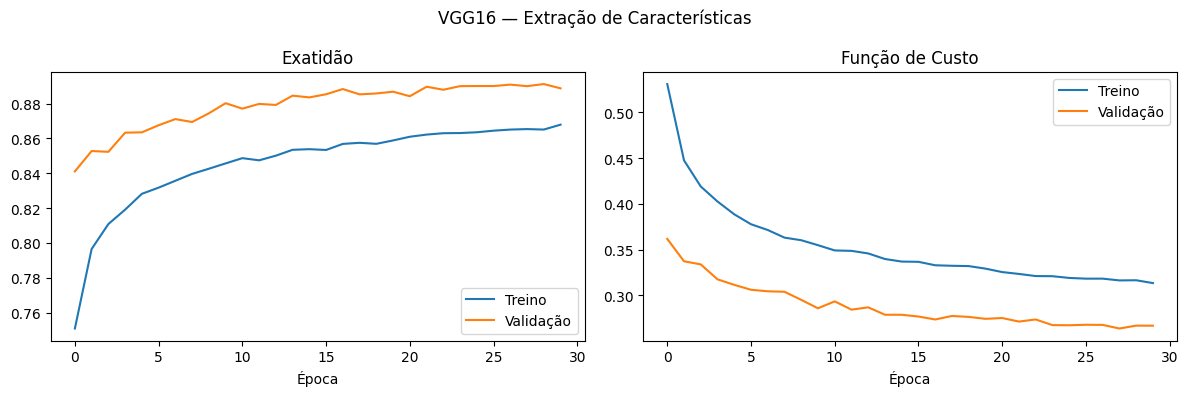

Épocas treinadas: 30


In [ ]:
plot_history(history_vgg_feat, 'VGG16 — Extração de Características')


In [ ]:
vgg_feat_model.save(MODEL_PATH + 'vgg16_feature_extraction.keras')
print('Modelo VGG16 Feature Extraction gravado.')

Modelo VGG16 Feature Extraction gravado.


In [ ]:
# Descomentar apenas se necessário recarregar
vgg_feat_model = load_model(MODEL_PATH + 'vgg16_feature_extraction.keras')

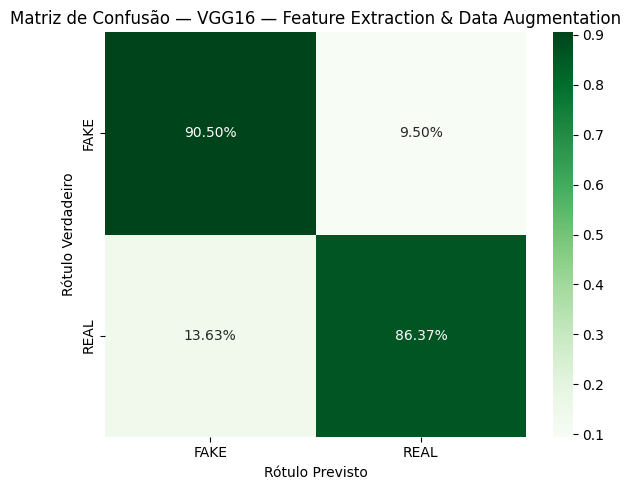

              precision    recall  f1-score   support

        FAKE       0.87      0.91      0.89     10000
        REAL       0.90      0.86      0.88     10000

    accuracy                           0.88     20000
   macro avg       0.89      0.88      0.88     20000
weighted avg       0.89      0.88      0.88     20000


--- Tabela Comparativa (até ao momento) ---


,Train Acc,Val Acc,Test Acc
CNN Raiz — Baseline,0.9582,0.9266,0.9244
"CNN Raiz — lr=0.0001, batch=64",0.9594,0.9377,0.9317
VGG16 — Feature Extraction & Data Augmentation,0.8804,0.8901,0.8843


In [ ]:
preds_vgg_feat, true_vgg, prob_vgg_feat = avaliar_modelo(
    vgg_feat_model, 'VGG16 — Feature Extraction & Data Augmentation',
    generator=vgg_test_gen,
    train_gen=vgg_train_gen, val_gen=vgg_val_gen
)


**Análise dos resultados — Feature Extraction:**

O modelo VGG16 com extração de características atingiu uma exatidão de teste de aproximadamente **88%**
(precision: FAKE ~87%, REAL ~90%). O treino atingiu o limite máximo de 30 épocas sem que o
EarlyStopping fosse activado, o que sugere que beneficiaria de treino adicional. Esta limitação
deveu-se a restrições de tempo de computação no ambiente Colab.

Ainda assim, o resultado é inferior ao da CNN de raiz (92–93%), o que parece contra-intuitivo. A explicação reside em dois fatores:

1. o VGG16 foi pré-treinado no
ImageNet com imagens naturais de 224×224px, enquanto o CIFAKE tem imagens de apenas 32×32px
redimensionadas para 48×48px — as representações aprendidas não se transferem de forma tão eficaz
para este domínio de baixa resolução;

2. com os pesos convolucionais totalmente congelados,
o modelo não consegue adaptar as suas representações ao domínio específico do CIFAKE.

---
### 5.2 Abordagem B: Ajuste Fino (Fine-Tuning)

Descongelam-se as últimas camadas convolucionais da VGG16 (bloco 5) e retreinam-se com uma taxa de aprendizagem muito baixa.  
Isto permite à rede adaptar as representações de alto nível às características específicas das imagens CIFAKE (REAL vs FAKE).


In [ ]:
#garantir que todas as camadas estão congeladas
vgg_base.trainable = False
#Descongelar as camadasdo bloco 5
for layer in vgg_base.layers[-4:]:
  layer.trainable = True

In [ ]:
# Confirmar quais estão descongeladas
pd.DataFrame(
    [(l.name, l.trainable) for l in vgg_base.layers],
    columns=['Camada', 'Treinável']
)


,Camada,Treinável
0,input_layer,False
1,block1_conv1,False
2,block1_conv2,False
3,block1_pool,False
4,block2_conv1,False
5,block2_conv2,False
6,block2_pool,False
7,block3_conv1,False
8,block3_conv2,False
9,block3_conv3,False


In [ ]:
# Arquitetura idêntica ao Feature Extraction, mas agora com bloco 5 descongelado
vgg_ft_model = Sequential()
vgg_ft_model.add(vgg_base)
vgg_ft_model.add(Flatten())
vgg_ft_model.add(Dense(512, activation='relu'))
vgg_ft_model.add(BatchNormalization())
vgg_ft_model.add(Dropout(0.3))
vgg_ft_model.add(Dense(256, activation='relu'))
vgg_ft_model.add(BatchNormalization())
vgg_ft_model.add(Dropout(0.3))
vgg_ft_model.add(Dense(1, activation='sigmoid'))

# RMSprop com taxa de aprendizagem baixa para fine-tuning seguro
vgg_ft_model.compile(
    optimizer=optimizers.RMSprop(learning_rate=2e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
vgg_ft_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 1, 1, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,112,001 (57.65 MB)

 Trainable params: 7,475,201 (28.52 MB)

 Non-trainable params: 7,636,800 (29.13 MB)

In [ ]:
es_ft = EarlyStopping(monitor='val_loss', patience=8,
                       restore_best_weights=True, verbose=1)

history_vgg_ft = vgg_ft_model.fit(
    vgg_train_gen,
    validation_data=vgg_val_gen,
    epochs=50,
    callbacks=[es_ft]
)


Epoch 1/50
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 131s 94ms/step - accuracy: 0.8311 - loss: 0.3972 - val_accuracy: 0.9117 - val_loss: 0.2201
Epoch 2/50
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 121s 91ms/step - accuracy: 0.8847 - loss: 0.2827 - val_accuracy: 0.9016 - val_loss: 0.2420
Epoch 3/50
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 120s 91ms/step - accuracy: 0.8987 - loss: 0.2493 - val_accuracy: 0.9342 - val_loss: 0.1675
Epoch 4/50
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 123s 93ms/step - accuracy: 0.9099 - loss: 0.2235 - val_accuracy: 0.9184 - val_loss: 0.2100
Epoch 5/50
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 124s 93ms/step - accuracy: 0.9188 - loss: 0.2060 - val_accuracy: 0.9096 - val_loss: 0.2286
Epoch 6/50
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 121s 91ms/step - accuracy: 0.9216 - loss: 0.1967 - val_accuracy: 0.9186 - val_loss: 0.2057
Epoch 7/50
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 124s 93ms/step - accuracy: 0.9266 - loss: 0.1861 - val_accuracy: 0.9186 - val_loss: 0.2060
Epoch 8/50
1329/1329 ━━━━━━━━━━━━━━━━━━━━ 120s 90ms/step - accuracy: 

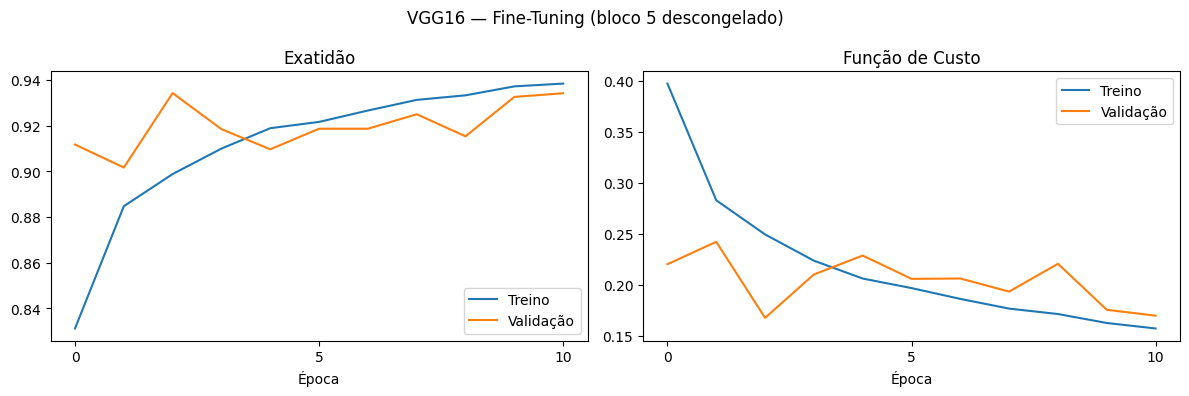

Épocas treinadas: 11


In [ ]:
plot_history(history_vgg_ft, 'VGG16 — Fine-Tuning (bloco 5 descongelado)')


In [ ]:
vgg_ft_model.save(MODEL_PATH + 'vgg16_fine_tuning.keras')
print('Modelo VGG16 Fine-Tuning gravado.')

Modelo VGG16 Fine-Tuning gravado.


In [ ]:
# Descomentar apenas se necessário recarregar
# vgg_ft_model = load_model(MODEL_PATH + 'vgg16_fine_tuning.keras')

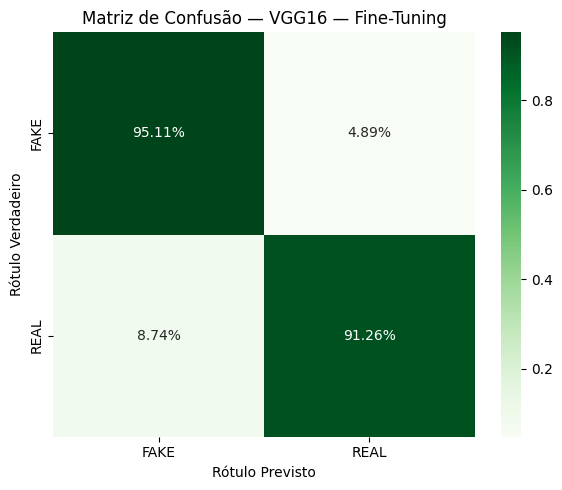

              precision    recall  f1-score   support

        FAKE       0.92      0.95      0.93     10000
        REAL       0.95      0.91      0.93     10000

    accuracy                           0.93     20000
   macro avg       0.93      0.93      0.93     20000
weighted avg       0.93      0.93      0.93     20000


--- Tabela Comparativa (até ao momento) ---


,Train Acc,Val Acc,Test Acc
CNN Raiz — Baseline,0.9582,0.9266,0.9244
"CNN Raiz — lr=0.0001, batch=64",0.9594,0.9377,0.9317
VGG16 — Feature Extraction & Data Augmentation,0.8804,0.8901,0.8843
VGG16 — Fine-Tuning,0.9136,0.9342,0.9318


In [ ]:
preds_vgg_ft, true_vgg_ft, prob_vgg_ft = avaliar_modelo(
    vgg_ft_model, 'VGG16 — Fine-Tuning',
    generator=vgg_test_gen,
    train_gen=vgg_train_gen, val_gen=vgg_val_gen
)


**Análise dos resultados — Fine-Tuning vs Feature Extraction:**

O Fine-Tuning com o bloco 5 descongelado atingiu **~93%** de exatidão de teste, recuperando
todo o desempenho perdido na extração de características e igualando a melhor CNN de raiz.
O EarlyStopping activou-se na época 11 (melhor época: 3).

O Fine-Tuning permitiu que o bloco 5 do VGG16 se adaptasse ao domínio CIFAKE, em vez de usar representações
fixas aprendidas no ImageNet. Esta especialização explica a recuperação de 5 pontos
percentuais face à extração de características (88% → 93%).

---
## 6. Comparação dos Modelos

Compara-se o desempenho de todos os modelos treinados num único quadro resumo.


In [ ]:
print('=== Tabela Comparativa Final ===\n')
display(
    performance
    .sort_values('Test Acc', ascending=False)
    .style.format('{:.4f}')
)


=== Tabela Comparativa Final ===



,Train Acc,Val Acc,Test Acc
VGG16 — Fine-Tuning,0.9136,0.9342,0.9318
"CNN Raiz — lr=0.0001, batch=64",0.9594,0.9377,0.9317
CNN Raiz — Baseline,0.9582,0.9266,0.9244
VGG16 — Feature Extraction & Data Augmentation,0.8804,0.8901,0.8843


**Comparação final dos modelos:**

O melhor modelo é o **VGG16 com Fine-Tuning**, empatado com a CNN v2 em 93%, mas com uma
diferença qualitativa importante: convergiu em apenas **11 épocas** contra 31 da CNN v2, e
beneficia de representações robustas pré-aprendidas no ImageNet.

O resultado do Feature Extraction (88%) ficou abaixo da CNN de raiz, confirmando que a
transferência directa de representações ImageNet para imagens CIFAKE de baixa resolução não
é eficaz sem adaptação. O Fine-Tuning resolve esse problema ao permitir que o bloco 5 se
especialize no domínio-alvo.

---
## 7. Análise de Erros do Melhor Modelo

Identificar o melhor modelo pela exatidão no conjunto de teste e analisar os seus erros:
- falsos positivos (FAKE classificado como REAL)
- falsos negativos (REAL classificado como FAKE)

procurando padrões que revelem limitações do modelo.


In [ ]:
# Selecionar as previsões do melhor modelo
best_preds    = preds_vgg_ft
best_probs    = prob_vgg_ft
best_y_true   = true_vgg_ft
best_name     = 'VGG16 — Fine-Tuning'

# Carregar todas as imagens de teste para visualização
vgg_test_gen.reset()
test_images_list = []
test_labels_list = []

for batch_imgs, batch_lbls in vgg_test_gen:
    test_images_list.append(batch_imgs)
    test_labels_list.append(batch_lbls)
    if len(np.concatenate(test_labels_list)) >= vgg_test_gen.samples:
        break

test_images_all = np.concatenate(test_images_list)[:vgg_test_gen.samples]
test_labels_all = np.concatenate(test_labels_list)[:vgg_test_gen.samples].astype(int)

# Índices dos erros
idx_erros = np.where(best_preds != test_labels_all)[0]
# Falsos Positivos: FAKE (0) previsto como REAL (1)
idx_fp = np.where((best_preds == 1) & (test_labels_all == 0))[0]
# Falsos Negativos: REAL (1) previsto como FAKE (0)
idx_fn = np.where((best_preds == 0) & (test_labels_all == 1))[0]

class_names_vgg = list(vgg_test_gen.class_indices.keys())
print(f'Total de erros   : {len(idx_erros)}')
print(f'Falsos Positivos : {len(idx_fp)}  (FAKE classificado como REAL)')
print(f'Falsos Negativos : {len(idx_fn)}  (REAL classificado como FAKE)')


Total de erros   : 1363
Falsos Positivos : 489  (FAKE classificado como REAL)
Falsos Negativos : 874  (REAL classificado como FAKE)


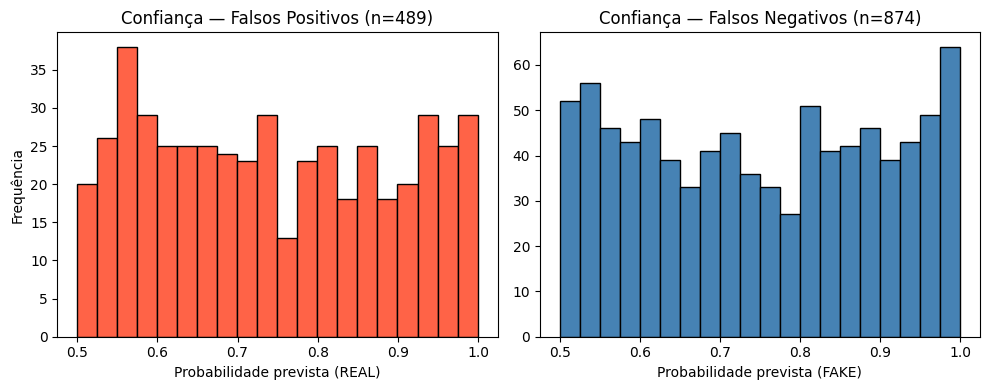

Confiança média nos Falsos Positivos : 0.7437
Confiança média nos Falsos Negativos : 0.7512


In [ ]:
# Análise da confiança nas previsões erradas

conf_fp = best_probs[idx_fp].flatten() if len(idx_fp) > 0 else np.array([])
conf_fn = best_probs[idx_fn].flatten() if len(idx_fn) > 0 else np.array([])

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
if len(conf_fp) > 0:
    plt.hist(conf_fp, bins=20, color='tomato', edgecolor='black')
    plt.title(f'Confiança — Falsos Positivos (n={len(idx_fp)})')
    plt.xlabel('Probabilidade prevista (REAL)')
    plt.ylabel('Frequência')

plt.subplot(1, 2, 2)
if len(conf_fn) > 0:
    plt.hist(1 - conf_fn, bins=20, color='steelblue', edgecolor='black')
    plt.title(f'Confiança — Falsos Negativos (n={len(idx_fn)})')
    plt.xlabel('Probabilidade prevista (FAKE)')

plt.tight_layout()
plt.show()

if len(conf_fp) > 0:
    print(f'Confiança média nos Falsos Positivos : {conf_fp.mean():.4f}')
if len(conf_fn) > 0:
    print(f'Confiança média nos Falsos Negativos : {(1 - conf_fn).mean():.4f}')

**Análise de erros — VGG16 Fine-Tuning (melhor modelo):**

O modelo cometeu **1363 erros** em 20000 imagens de teste:
- **Falsos Positivos: 489** — imagens FAKE classificadas como REAL
- **Falsos Negativos: 874** — imagens REAL classificadas como FAKE

O número de Falsos Negativos é **quase o dobro** dos Falsos Positivos, o que indica que o
modelo tem maior dificuldade em reconhecer imagens reais do que imagens geradas. Isto é
consistente com o facto de as imagens CIFAKE reais serem provenientes do CIFAR-10, imagens
naturais de baixa resolução que, após redimensionamento, podem apresentar características
visuais semelhantes às de imagens sintéticas.

A confiança média nas previsões erradas é elevada e semelhante em ambos os tipos de erro
(FP: **74.4%**, FN: **75.1%**), o que revela que o modelo erra com convicção, não hesita
nas suas previsões incorrectas.

Esta é uma limitação relevante em aplicações reais. Um modelo com elevada confiança
nos erros não fornece qualquer sinal de alerta ao utilizador, ao contrário de um modelo
que expressasse incerteza (probabilidades próximas de 0.5) nas previsões incorrectas.

Em conjunto, estes padrões sugerem que a principal limitação do modelo é a resolução reduzida
das imagens, que limita a quantidade de informação visual disponível para distinguir
artefactos de geração de variações
naturais presentes em fotografias reais.

## 8. Conclusões

O Fine-Tuning do VGG16 e a CNN v2 de raiz atingiram ambos **93% de exatidão** no conjunto
de teste, sendo o Fine-Tuning preferível pela convergência mais rápida (11 épocas vs 31)
e pela robustez das representações pré-treinadas. A extração de características ficou aquém
(88%), confirmando que representações ImageNet não se transferem directamente para imagens
de baixa resolução sem adaptação ao domínio.

| Modelo | Test Acc | Épocas |
|---|---|---|
| CNN Baseline | 92% | 20 |
| CNN v2 | 93% | 31 |
| VGG16 Feature Extraction | 88% | 30 |
| VGG16 Fine-Tuning | **93%** | 11 |

**Limitações:**
- Resolução muito baixa (32×32) oculta artefactos típicos de IA e limita todos os modelos.
- O modelo foi treinado com imagens geradas exclusivamente por Stable Diffusion v1.4. A generalização para outras ferramentas generativas é incerta.
- A detecção de imagens geradas por IA é um problema em evolução constante. Modelos generativos mais recentes produzem imagens progressivamente mais difíceis de detectar.